# Formative 2 – Part 2: Image Data & Face Recognition Model
**Owner:** Member 2 (Kate) &nbsp;|&nbsp; **Notebook:** `notebooks/02_image.ipynb`

**Goal.** Process and augment the team's face photos, extract features into `data/image_features.csv`, and train a model that
**recognizes each team member and rejects strangers**. The function `predict_face(image_path)` (in `scripts/face_model.py`) is used by
the command-line app as the first security check.

**Steps:** 1 Setup → 2 Check images → 3 Display → 4 Augment → 5 Extract features → 6 Train → 7 Evaluate → 8 Reject strangers (threshold) → 9 Save and test.

Random seed **42** is used everywhere. The reusable code lives in `scripts/face_model.py`; this notebook calls it step by step and shows the results.

## 1. Setup

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

# Find the repository root whether the notebook is run from the root or from notebooks/
ROOT = os.path.abspath(".." if os.path.basename(os.getcwd()) == "notebooks" else ".")
sys.path.insert(0, os.path.join(ROOT, "scripts"))
import face_model as fm

BACKEND = fm.default_backend()
print("Repository root:", ROOT)
print("Feature backend:", BACKEND, "(facenet = pretrained FaceNet embeddings, classic = HOG + colour histogram)")

Repository root: D:\ALU_Trials\dataPreProcessing
Feature backend: facenet (facenet = pretrained FaceNet embeddings, classic = HOG + colour histogram)


## 2. Check the images
Every member should have 3 photos (neutral, smiling, surprised), named `firstname_expression.jpg`, similar in size.

In [2]:
import glob, os
for p in sorted(glob.glob(os.path.join(ROOT, "data", "images", "**", "*"), recursive=True)):
    if os.path.isfile(p):
        print(p)

D:\ALU_Trials\dataPreProcessing\data\images\amazing\amazing_neutral.jpeg
D:\ALU_Trials\dataPreProcessing\data\images\amazing\amazing_smiling.png
D:\ALU_Trials\dataPreProcessing\data\images\amazing\amazing_surprised.jpeg
D:\ALU_Trials\dataPreProcessing\data\images\gilbert\gilbert_neutral.jpeg
D:\ALU_Trials\dataPreProcessing\data\images\gilbert\gilbert_smiling.jpeg
D:\ALU_Trials\dataPreProcessing\data\images\gilbert\gilbert_surprised.jpeg
D:\ALU_Trials\dataPreProcessing\data\images\kate\kate_neutral.jpeg
D:\ALU_Trials\dataPreProcessing\data\images\kate\kate_smiling.jpeg
D:\ALU_Trials\dataPreProcessing\data\images\kate\kate_surprised.jpeg


In [3]:
items = fm.list_member_images()
inv = pd.DataFrame(items)
inv["width"], inv["height"] = zip(*[fm.load_rgb(p).size for p in inv["path"]])

# 1) does each member have all three expressions?
table = pd.crosstab(inv["member"], inv["expression"]).reindex(columns=fm.EXPRESSIONS, fill_value=0)
print("Photos per member and expression (each cell should be 1):")
display(table)
missing = [(m, e) for m in table.index for e in fm.EXPRESSIONS if table.loc[m, e] != 1]
print("Missing / duplicated photos:", missing if missing else "none")

# 2) are the sizes similar?
display(inv[["member", "expression", "width", "height"]].sort_values(["member", "expression"]).reset_index(drop=True))
print("Image sizes found:", inv.groupby(["width", "height"]).size().to_dict())

Photos per member and expression (each cell should be 1):


expression,neutral,smiling,surprised
member,,,
Amazing,1,1,1
Gilbert,1,1,1
Kate,1,1,1


Missing / duplicated photos: none


,member,expression,width,height
0,Amazing,neutral,922,1152
1,Amazing,smiling,391,589
2,Amazing,surprised,922,1152
3,Gilbert,neutral,810,1080
4,Gilbert,smiling,810,1080
5,Gilbert,surprised,810,1080
6,Kate,neutral,960,1280
7,Kate,smiling,960,1280
8,Kate,surprised,960,1280


Image sizes found: {(391, 589): 1, (810, 1080): 3, (922, 1152): 2, (960, 1280): 3}


## 3. Display the photos (one labelled grid per member)

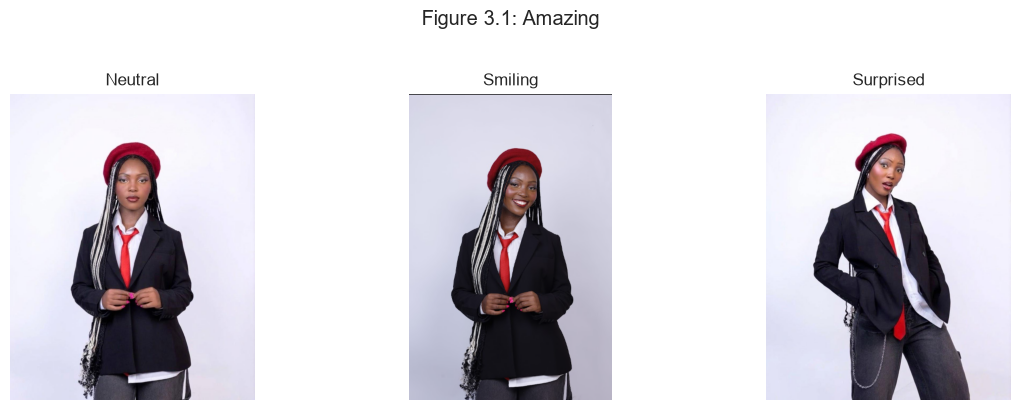

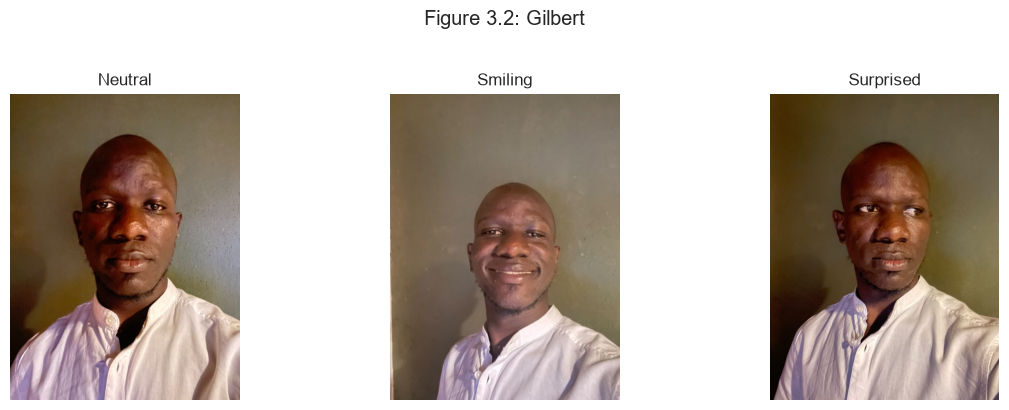

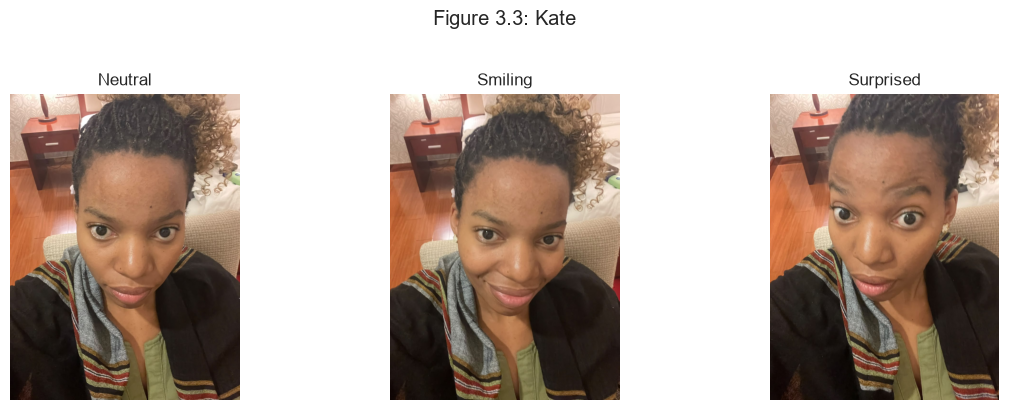

In [4]:
for member, grp in inv.groupby("member"):
    grp = grp.set_index("expression").reindex([e for e in fm.EXPRESSIONS if e in set(grp["expression"])])
    fig, axes = plt.subplots(1, len(grp), figsize=(4 * len(grp), 4))
    axes = np.atleast_1d(axes)
    for ax, (expr, row) in zip(axes, grp.iterrows()):
        ax.imshow(fm.load_rgb(row["path"])); ax.set_title(expr.capitalize()); ax.axis("off")
    fig.suptitle(f"Figure 3.{list(inv['member'].unique()).index(member) + 1}: {member}", y=1.02)
    plt.tight_layout(); plt.show()

## 4. Augmentation
The dataset is tiny (3 photos per person), so every photo is augmented with **six** changes: rotation ±15°, horizontal flip,
brighter, darker and grayscale. These simulate a slightly tilted head, a mirrored selfie and different lighting. Augmented images are
saved to `data/images_augmented/`.

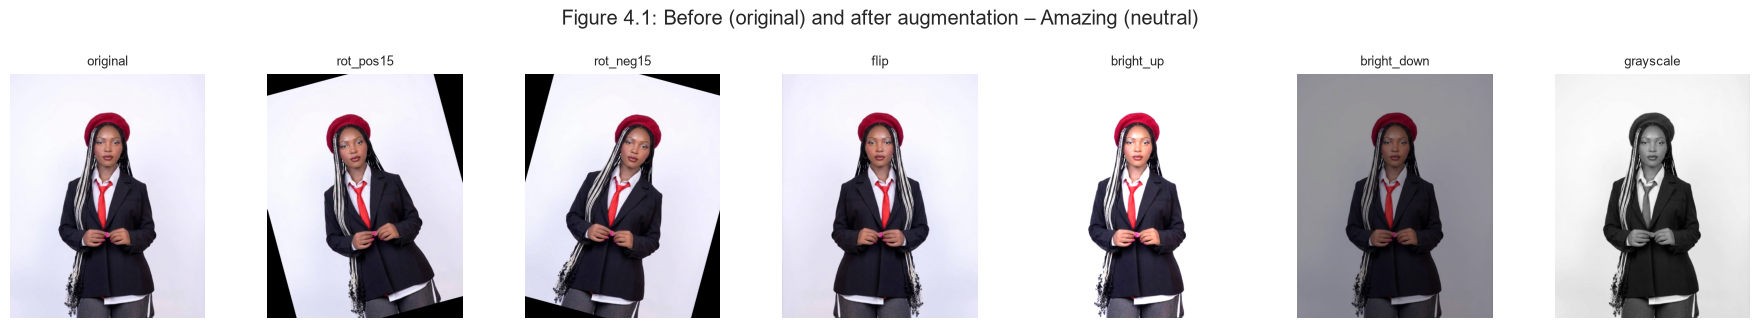

In [5]:
example = items[0]
img = fm.load_rgb(example["path"])
names = ["original"] + list(fm.AUGMENTATIONS)
fig, axes = plt.subplots(1, len(names), figsize=(2.6 * len(names), 3.2))
for ax, n in zip(axes, names):
    ax.imshow(img if n == "original" else fm.AUGMENTATIONS[n](img)); ax.set_title(n, fontsize=9); ax.axis("off")
fig.suptitle(f"Figure 4.1: Before (original) and after augmentation – {example['member']} ({example['expression']})", y=1.02)
plt.tight_layout(); plt.show()

## 5. Feature extraction
Each image (original and augmented) becomes one row of numbers.
* **`facenet` backend:** a pretrained FaceNet network finds and crops the face and returns a 512-number *embedding* – photos of the same
  person give similar embeddings. This is the main, recommended feature set.
* **`classic` backend (fallback):** HOG shape features of the grayscale image plus an HSV colour histogram.

The table is saved to `data/image_features.csv` with the columns member, expression, source image, augmentation type and the features.

In [6]:
features = fm.build_feature_table(backend=BACKEND, verbose=False)
FEAT = fm.feature_columns(features)
print("Saved:", fm.FEATURES_PATH)
print("Rows:", len(features), "| feature columns:", len(FEAT), "| backend:", BACKEND)
print("\nRows per member:\n", features["member"].value_counts().to_string())
print("\nRows per augmentation type:\n", features["augmentation"].value_counts().to_string())
features.iloc[:5, :8]

Saved: D:\ALU_Trials\dataPreProcessing\data\image_features.csv
Rows: 63 | feature columns: 512 | backend: facenet

Rows per member:
 member
Amazing    21
Gilbert    21
Kate       21

Rows per augmentation type:
 augmentation
original       9
rot_pos15      9
rot_neg15      9
flip           9
bright_up      9
bright_down    9
grayscale      9


,member,expression,source_image,augmentation,f_000,f_001,f_002,f_003
0,Amazing,neutral,amazing_neutral,original,-0.060305,-0.070551,-0.096339,-0.011475
1,Amazing,neutral,amazing_neutral,rot_pos15,-0.059198,-0.095565,-0.100805,-0.016012
2,Amazing,neutral,amazing_neutral,rot_neg15,-0.064269,-0.081304,-0.102382,-0.013244
3,Amazing,neutral,amazing_neutral,flip,-0.058319,-0.082097,-0.098879,-0.015777
4,Amazing,neutral,amazing_neutral,bright_up,-0.061372,-0.078659,-0.098305,-0.008960


## 6. Train and compare models
* **Target:** the member's name (a multi-class classification problem).
* **Split without leakage:** every augmented image is a copy of an original photo. If a copy were in the training set and its original in the
  test set, the scores would be unrealistically high. We therefore use **`GroupKFold` grouped by the original photo** (`source_image`), so an
  original and all its augmentations are always on the same side of the split.
* **Models:** Logistic Regression (with scaling) and Random Forest. Metrics: accuracy, macro F1 and log loss.

In [7]:
X = features[FEAT].values
y = features["member"].values
groups = features["source_image"].values

results, oof_store = {}, {}
for name, make in fm.make_models().items():
    oof, classes = fm.grouped_cv_proba(X, y, groups, make)
    oof_store[name] = oof
    results[name] = fm.score_oof(y, oof, classes)
comparison = pd.DataFrame(results).T.round(3)
print("Grouped cross-validation (folds split by original photo):")
display(comparison)

best_name = comparison["f1_macro"].idxmax()
print("Best model by macro F1:", best_name)

Grouped cross-validation (folds split by original photo):


,accuracy,f1_macro,log_loss
Logistic Regression,1.0,1.0,0.002
Random Forest,1.0,1.0,0.196


Best model by macro F1: Logistic Regression


## 7. Evaluate the best model

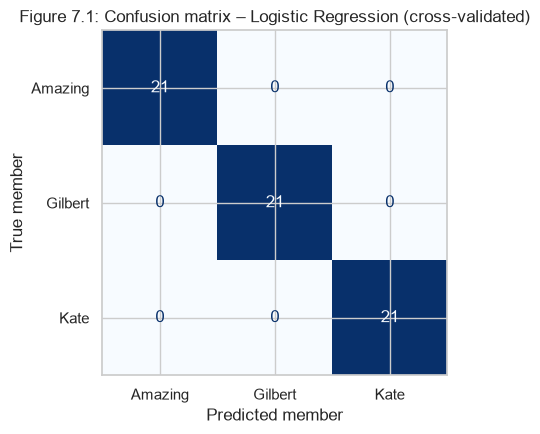

              precision    recall  f1-score   support

     Amazing       1.00      1.00      1.00        21
     Gilbert       1.00      1.00      1.00        21
        Kate       1.00      1.00      1.00        21

    accuracy                           1.00        63
   macro avg       1.00      1.00      1.00        63
weighted avg       1.00      1.00      1.00        63



In [8]:
oof = oof_store[best_name]
pred = classes[oof.argmax(axis=1)]
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y, pred, labels=classes), display_labels=classes).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Figure 7.1: Confusion matrix – {best_name} (cross-validated)")
ax.set_xlabel("Predicted member"); ax.set_ylabel("True member")
plt.tight_layout(); plt.show()
print(classification_report(y, pred, zero_division=0))

Both models classified every image correctly under grouped cross-validation (accuracy = 1.000, macro F1 = 1.000), so the confusion matrix has no errors for any member or expression; Logistic Regression was chosen because its log loss (0.002) was much lower than Random Forest's (0.197). These scores are not strong evidence of generalization, because FaceNet is pretrained to separate identities and we only had 9 original photos (3 per person) from the same sessions, with the augmented images being variations of those photos rather than new samples. Performance on new lighting, backgrounds or angles may therefore be lower.

## 8. Reject strangers with a confidence threshold
The model only knows the team members, so it will always name *someone*. We use the **highest predicted probability as the confidence**. If it is below
a threshold, `predict_face` returns `"unknown"`. The threshold is chosen between the confidence the model gives the **non-member photo(s)** in
`data/unauthorized/` and the confidence it gives (held-out) member photos.

Frank_neutral.jpeg           -> best match Kate     confidence 0.921


Frank_smiling.jpeg           -> best match Kate     confidence 0.942


Frank_surprised.jpeg         -> best match Kate     confidence 0.898


Placide_neutral.jpeg         -> best match Kate     confidence 0.723


Placide_smiling.jpeg         -> best match Kate     confidence 0.672


Placide_surprised.jpeg       -> best match Kate     confidence 0.612
strangy_facy.png             -> best match Amazing  confidence 0.879


stray_fac.png                -> best match Amazing  confidence 0.570

Member confidence (held-out originals): min 0.995, 10th percentile 0.997
Stranger confidence: [0.921, 0.942, 0.898, 0.723, 0.672, 0.612, 0.879, 0.57]
Chosen threshold: 0.970


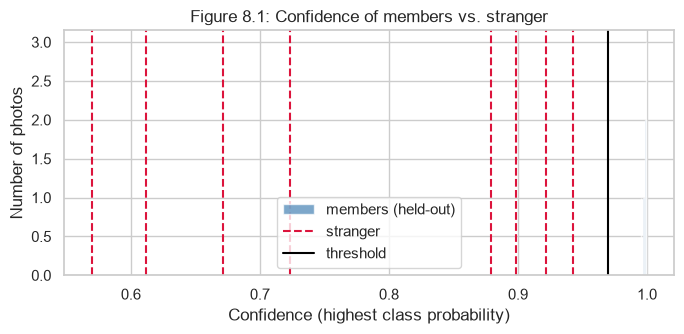

In [9]:
final_model = fm.fit_final(features, best_name)

# confidence on held-out ORIGINAL member photos that were classified correctly
is_orig = (features["augmentation"] == "original").values
correct = oof.argmax(axis=1) == np.searchsorted(classes, y)
member_conf = oof.max(axis=1)[is_orig & correct]

# confidence of the final model on the non-member photo(s)
unauth_files = fm.list_unauthorized_images()
stranger_conf = []
for p in unauth_files:
    proba = final_model.predict_proba(fm.extract_features(fm.load_rgb(p), BACKEND).reshape(1, -1))[0]
    stranger_conf.append(float(proba.max()))
    print(f"{os.path.basename(p):28s} -> best match {final_model.classes_[proba.argmax()]:8s} confidence {proba.max():.3f}")
if not unauth_files:
    print("No non-member photo in data/unauthorized/ yet - using the default threshold.")

THRESHOLD = fm.choose_threshold(member_conf, stranger_conf)
print(f"\nMember confidence (held-out originals): min {member_conf.min():.3f}, 10th percentile {np.percentile(member_conf, 10):.3f}")
print(f"Stranger confidence: {np.round(stranger_conf, 3).tolist()}")
print(f"Chosen threshold: {THRESHOLD:.3f}")

plt.figure(figsize=(7, 3.5))
plt.hist(member_conf, bins=10, alpha=.7, label="members (held-out)", color="steelblue")
for s in stranger_conf: plt.axvline(s, color="crimson", ls="--", label="stranger" if s == stranger_conf[0] else None)
plt.axvline(THRESHOLD, color="black", label="threshold")
plt.xlabel("Confidence (highest class probability)"); plt.ylabel("Number of photos")
plt.title("Figure 8.1: Confidence of members vs. stranger"); plt.legend(); plt.tight_layout(); plt.show()

## 9. Save the model and test `predict_face`

In [10]:
bundle = fm.save_model(final_model, BACKEND, THRESHOLD, best_name, FEAT)
print("Saved", fm.MODEL_PATH, "| model:", bundle["model_name"], "| threshold:", round(bundle["threshold"], 3))

rows = []
for it in items:
    name, conf = fm.predict_face(it["path"])
    rows.append({"file": os.path.basename(it["path"]), "expected": it["member"], "predicted": name,
                 "confidence": round(conf, 3), "OK": name == it["member"]})
for p in unauth_files:
    name, conf = fm.predict_face(p)
    rows.append({"file": os.path.basename(p), "expected": "unknown", "predicted": name,
                 "confidence": round(conf, 3), "OK": name == "unknown"})
test = pd.DataFrame(rows)
display(test)
print("All predictions as expected:", bool(test["OK"].all()))

Saved D:\ALU_Trials\dataPreProcessing\models\face_model.pkl | model: Logistic Regression | threshold: 0.97


,file,expected,predicted,confidence,OK
0,amazing_neutral.jpeg,Amazing,Amazing,1.000,True
1,amazing_smiling.png,Amazing,Amazing,1.000,True
2,amazing_surprised.jpeg,Amazing,Amazing,0.999,True
3,gilbert_neutral.jpeg,Gilbert,Gilbert,1.000,True
4,gilbert_smiling.jpeg,Gilbert,Gilbert,1.000,True
5,gilbert_surprised.jpeg,Gilbert,Gilbert,1.000,True
6,kate_neutral.jpeg,Kate,Kate,0.999,True
7,kate_smiling.jpeg,Kate,Kate,0.999,True
8,kate_surprised.jpeg,Kate,Kate,0.999,True
9,Frank_neutral.jpeg,unknown,unknown,0.921,True


All predictions as expected: True


In [11]:
fn = fm._get_facenet()
bad = []
for it in items:
    img = fm.load_rgb(it["path"])
    for aug in ["original"] + list(fm.AUGMENTATIONS):
        im = img if aug == "original" else fm.AUGMENTATIONS[aug](img)
        if fn["mtcnn"](im) is None:
            bad.append((it["source_image"], aug))
print("No face detected in:", bad if bad else "none")

No face detected in: none


**Note.** The member photos in this last test were part of the training data, so they are *expected* to be recognised – the honest estimate of performance
is the cross-validated result in section 7. The stranger test is the real check of the threshold.

## Summary
* Photos checked, displayed and augmented (6 augmentations per photo) → `data/images_augmented/`.
* Features for every original and augmented image → `data/image_features.csv`.
* Models compared with `GroupKFold` split by original photo (no leakage); best model saved to `models/face_model.pkl`.
* Confidence threshold chosen with the non-member photo(s); `predict_face` returns `"unknown"` below it.
* **Main limitation:** only 3 original photos per person and very few stranger photos, so accuracy and the threshold are estimated from very little data.